# 03 · Modelagem, avaliação e interpretação
Fluxo (tudo em `src/train.py`, `random_state=42`): split 80/20 estratificado → **CV aninhada** no treino → `GridSearchCV` otimizando **PR-AUC** →
limiar 0,5 *e* limiar F1-ótimo (via *out-of-fold* do treino) → avaliação única no teste + IC bootstrap.
O teste **não** participa de nenhuma escolha.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":      # funciona rodando de notebooks/ ou da raiz do repositório
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import config, eda
from src.preprocessing import carregar_dados, criar_alvo, NOMES_PT

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
CAMINHO = config.resolve_data_path()
print("BASE USADA:", CAMINHO.name, "" if config.is_official(CAMINHO) else
      f"  <-- ATENÇÃO: não é a base oficial ({config.OFFICIAL_DATASET}); execução de ENSAIO")
df = carregar_dados(CAMINHO)
config.ensure_dirs()
from src import train, report, evaluate
RS = config.RANDOM_STATE

BASE USADA: WineQT.csv 


## 1. Treino e comparação (≈ 2 min)

In [2]:
r = train.executar(df, remover_dup=config.REMOVE_DUPLICATES)

Duplicatas removidas: 125 de 1143 (10.9%) -> 1018 linhas
Treino: 814 | Teste: 204 | classe alta no teste: 27
Linhas do teste com cópia exata no treino: 0 (0.0%)
-> Regressão Logística


-> Decision Tree


-> Random Forest


## 2. Validação cruzada aninhada — média ± desvio-padrão entre folds

In [3]:
display(report.tabela_cv(r["cv"]))
print("Hiperparâmetros escolhidos:", r["params"])

,Modelo,ROC-AUC,PR-AUC,F1 (alta),Recall (alta),Precision (alta)
0,Regressão Logística,"0,882 ± 0,041","0,570 ± 0,119","0,503 ± 0,041","0,800 ± 0,094","0,367 ± 0,025"
1,Decision Tree,"0,812 ± 0,092","0,428 ± 0,144","0,468 ± 0,084","0,755 ± 0,186","0,340 ± 0,050"
2,Random Forest,"0,873 ± 0,050","0,553 ± 0,147","0,485 ± 0,127","0,591 ± 0,255","0,430 ± 0,065"


Hiperparâmetros escolhidos: {'Regressão Logística': {'C': 0.1}, 'Decision Tree': {'max_depth': 5, 'min_samples_leaf': 20}, 'Random Forest': {'max_depth': None, 'min_samples_leaf': 5}}


## 3. Teste — todas as métricas da classe alta

In [4]:
cols = ["modelo","decisao","accuracy","precision_alta","recall_alta","f1_alta","roc_auc","pr_auc"]
display(r["teste"][cols].round(3))
ic = pd.DataFrame([{"modelo": n, "decisao": d, **{k: f"[{a:.2f}; {b:.2f}]" for k,(a,b) in v.items()}} for (n,d),v in r["ics"].items()])
display(Markdown("**IC 95% por bootstrap no teste** (largos: poucos positivos no teste)")); display(ic)

,modelo,decisao,accuracy,precision_alta,recall_alta,f1_alta,roc_auc,pr_auc
0,Regressão Logística,"limiar 0,5",0.804,0.386,0.815,0.524,0.897,0.493
1,Regressão Logística,limiar ótimo F1 (OOF treino),0.863,0.486,0.630,0.548,0.897,0.493
2,Decision Tree,"limiar 0,5",0.809,0.389,0.778,0.519,0.860,0.492
3,Decision Tree,limiar ótimo F1 (OOF treino),0.824,0.408,0.741,0.526,0.860,0.492
4,Random Forest,"limiar 0,5",0.887,0.559,0.704,0.623,0.918,0.693
5,Random Forest,limiar ótimo F1 (OOF treino),0.877,0.526,0.741,0.615,0.918,0.693


**IC 95% por bootstrap no teste** (largos: poucos positivos no teste)

,modelo,decisao,recall_alta_ic95,precision_alta_ic95,f1_alta_ic95,roc_auc_ic95,pr_auc_ic95
0,Regressão Logística,"limiar 0,5",[0.67; 0.96],[0.25; 0.52],[0.38; 0.64],[0.84; 0.94],[0.33; 0.72]
1,Regressão Logística,limiar ótimo F1 (OOF treino),[0.45; 0.82],[0.31; 0.65],[0.38; 0.68],[0.84; 0.94],[0.33; 0.72]
2,Decision Tree,"limiar 0,5",[0.62; 0.93],[0.26; 0.52],[0.37; 0.65],[0.78; 0.93],[0.31; 0.67]
3,Decision Tree,limiar ótimo F1 (OOF treino),[0.57; 0.91],[0.26; 0.56],[0.37; 0.65],[0.78; 0.93],[0.31; 0.67]
4,Random Forest,"limiar 0,5",[0.52; 0.88],[0.37; 0.74],[0.46; 0.75],[0.86; 0.96],[0.51; 0.84]
5,Random Forest,limiar ótimo F1 (OOF treino),[0.57; 0.90],[0.35; 0.68],[0.45; 0.74],[0.86; 0.96],[0.51; 0.84]


## 4. Matrizes de confusão e curvas

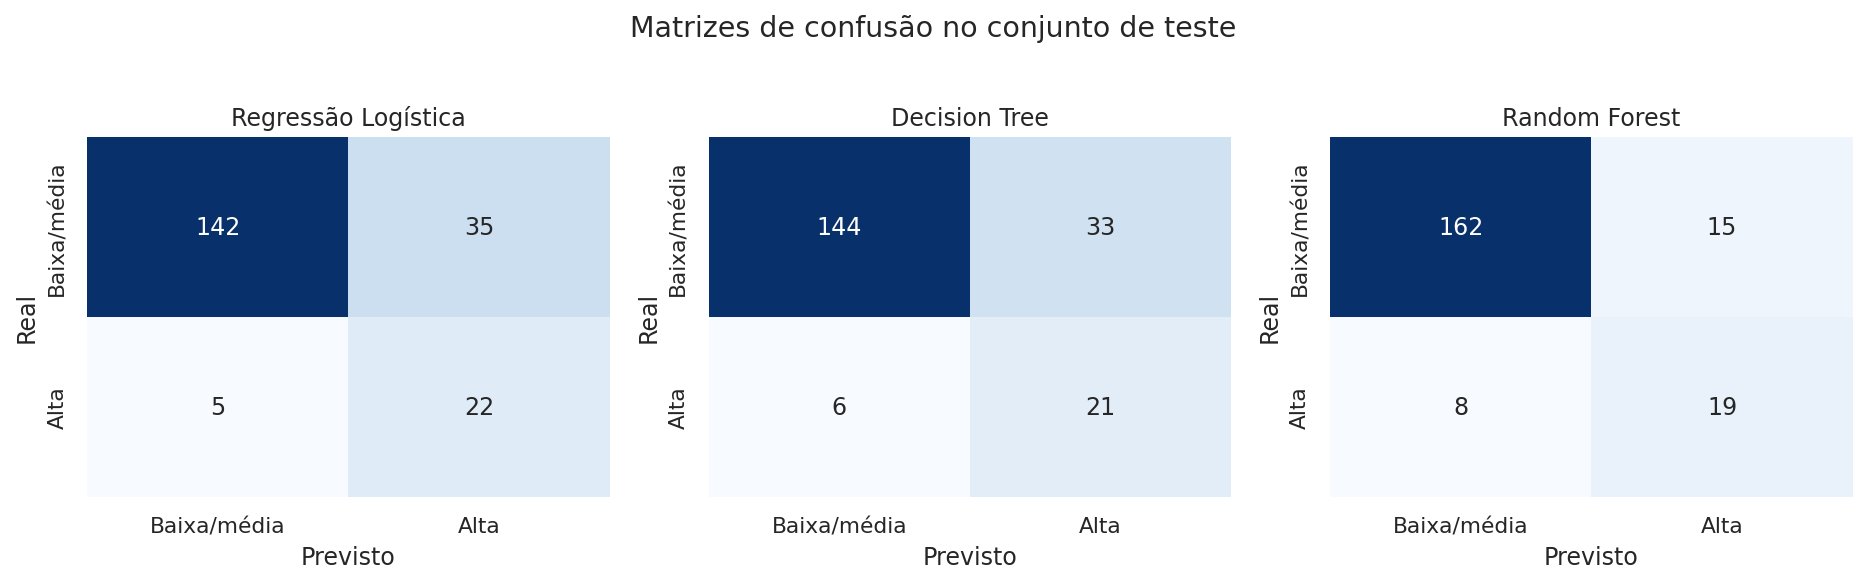

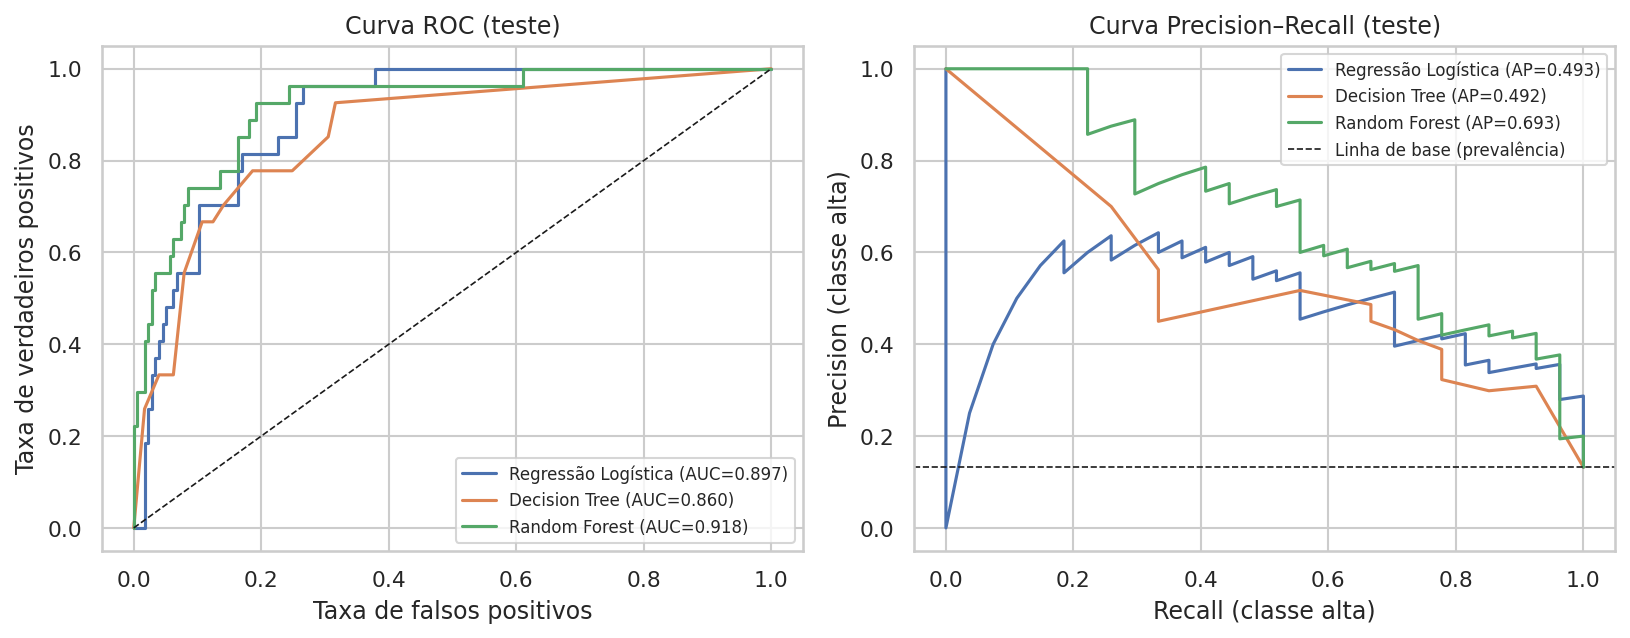

In [5]:
from IPython.display import Image
display(Image(str(config.RESULTS_DIR / "confusion_matrices.png")))
display(Image(str(config.FIG_DIR / "curvas_roc_pr.png")))

## 5. Escolha do modelo (regra do 1 desvio-padrão, só com a CV)

In [6]:
display(Markdown(f"**Modelo escolhido: {r['melhor_modelo']}** — {r['justificativa_modelo']}."))

**Modelo escolhido: Regressão Logística** — maior PR-AUC média na CV aninhada (0,570 ± 0,119).

## 6. Variáveis mais influentes
Três visões **preditivas** (nenhuma é causal): permutação no teste, importância por impureza (árvores) e coeficiente padronizado (linear), com estabilidade do sinal em 200 bootstraps.

,modelo,variavel,perm_importance_media,perm_importance_dp,coef_padronizado,estabilidade_sinal_bootstrap,impurity_importance
10,Regressão Logística,alcohol,0.1249,0.0554,1.0210,1.000,NaN
9,Regressão Logística,sulphates,0.0769,0.0379,0.7290,1.000,NaN
1,Regressão Logística,volatile_acidity,0.0472,0.0295,-0.4495,1.000,NaN
5,Regressão Logística,free_sulfur_dioxide,0.0195,0.0158,0.2421,0.925,NaN
6,Regressão Logística,total_sulfur_dioxide,0.0192,0.0276,-0.5347,1.000,NaN
2,Regressão Logística,citric_acid,0.0068,0.0076,0.0839,0.705,NaN
0,Regressão Logística,fixed_acidity,0.0037,0.0249,0.1842,0.855,NaN
7,Regressão Logística,density,-0.0005,0.0184,-0.2086,0.960,NaN
4,Regressão Logística,chlorides,-0.0033,0.0199,-0.4197,1.000,NaN
8,Regressão Logística,ph,-0.0057,0.0295,-0.2938,0.990,NaN


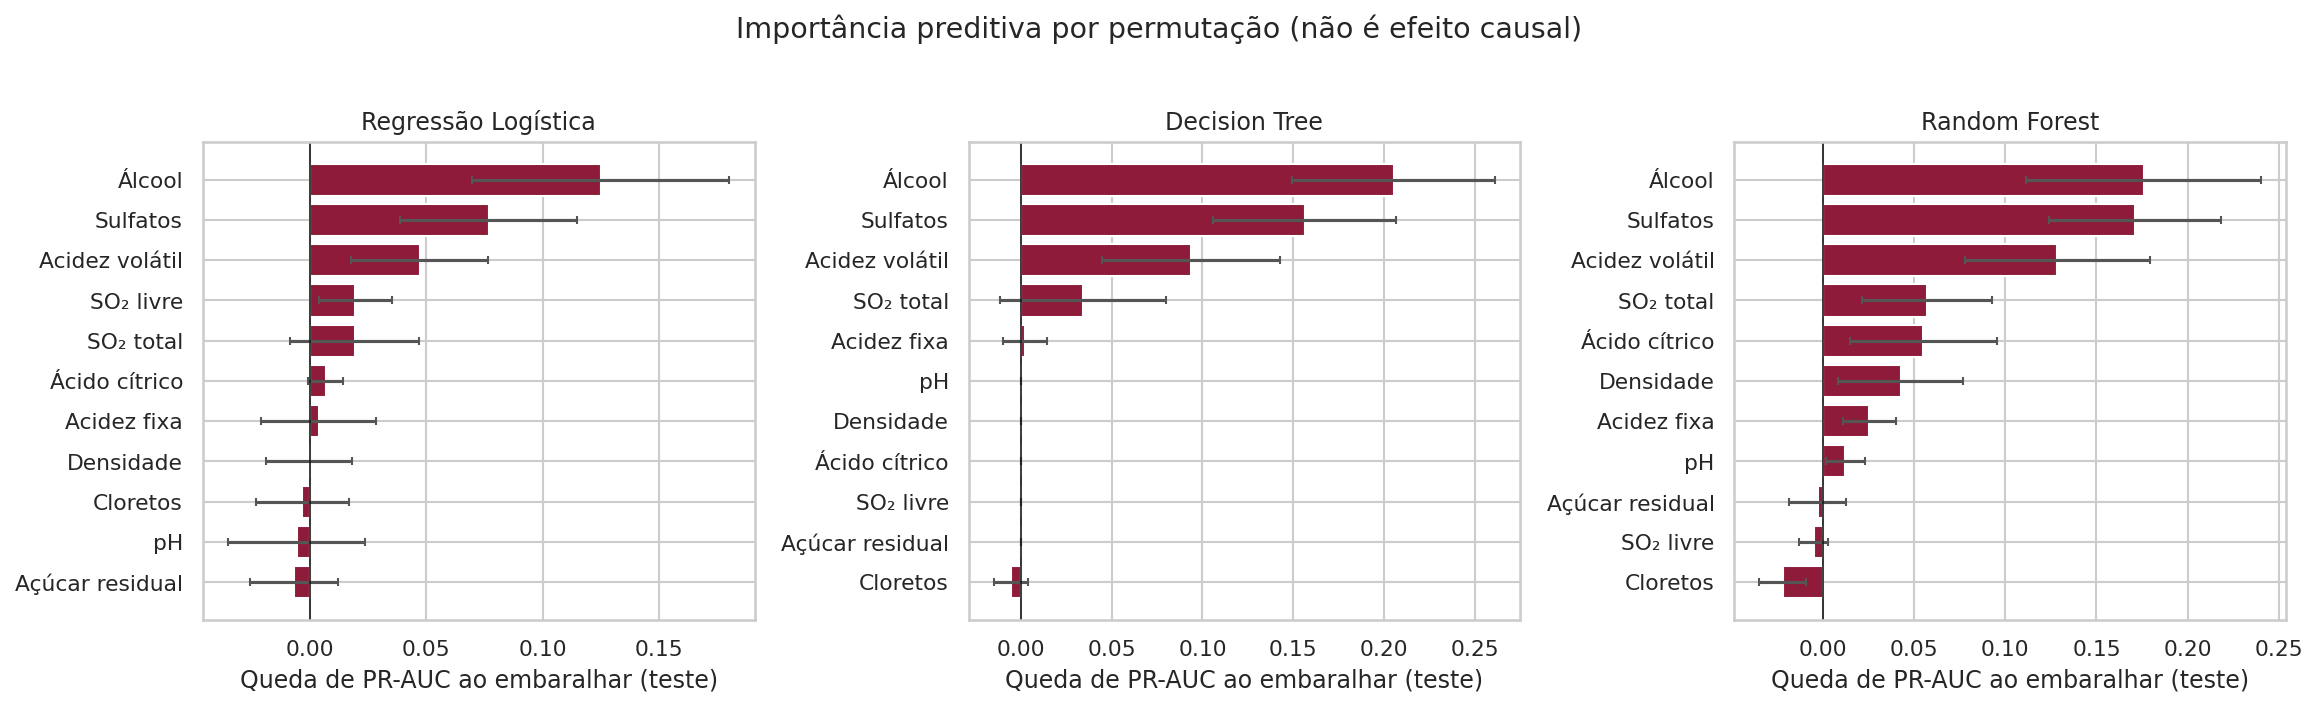

In [7]:
imp = r["importancias"]
display(imp[imp.modelo==r["melhor_modelo"]].sort_values("perm_importance_media", ascending=False).round(4))
display(Image(str(config.RESULTS_DIR / "feature_importance.png")))

## 7. Sensibilidade a duplicatas (≈ 3-4 min)

In [8]:
sens = train.sensibilidade_duplicatas(df, verbose=False)
display(report.tabela_sens(sens))

,Cenário,Linhas,Teste c/ cópia no treino,Modelo,ROC-AUC teste,PR-AUC teste,F1 alta (teste),PR-AUC CV
0,com duplicatas (split aleatório),1143,34,Regressão Logística,"0,832","0,515","0,489","0,558"
1,com duplicatas (split aleatório),1143,34,Decision Tree,"0,836","0,505","0,471","0,446"
2,com duplicatas (split aleatório),1143,34,Random Forest,"0,905","0,738","0,604","0,642"
3,sem duplicatas,1018,0,Regressão Logística,"0,897","0,493","0,524","0,570"
4,sem duplicatas,1018,0,Decision Tree,"0,860","0,492","0,519","0,428"
5,sem duplicatas,1018,0,Random Forest,"0,918","0,693","0,623","0,553"


## 8. Salvar resultados e regenerar README/slides/roteiro

Arquivos em: /home/claude/wine-quality-classification/results


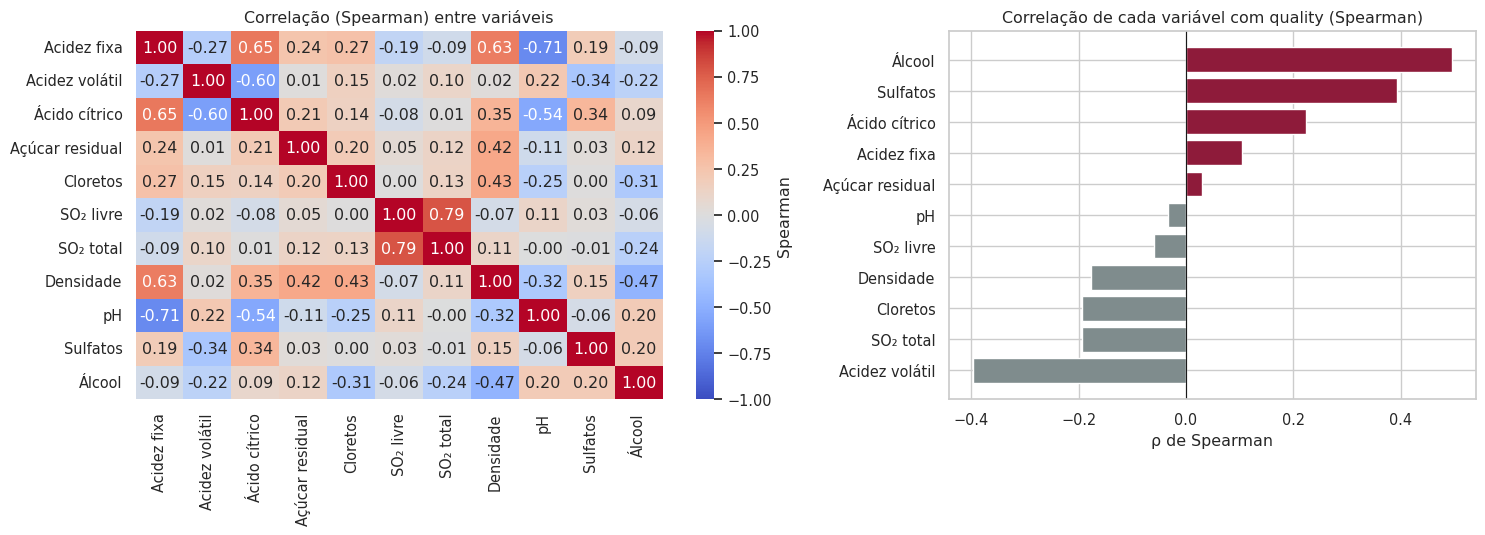

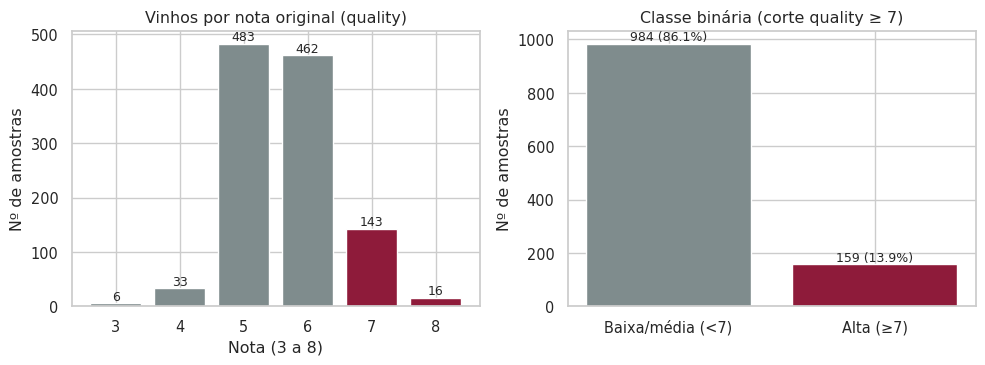

In [9]:
train.salvar_resultados(r, sens, eda.resumo_estrutural(df), CAMINHO)
report.gerar_tudo()
print("Arquivos em:", config.RESULTS_DIR)